[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C12/E12-3_Usure_Outil_CORRIGE.ipynb)

# Usure d'un outil de coupe : prévoir à plusieurs horizons

## Le contexte

Cinquante-quatre plaquettes de tournage sont suivies de la plaquette neuve jusqu'à leur retrait. Chaque minute de coupe, l'usure en dépouille VB est mesurée au microscope, au centième de millimètre. Une plaquette est retirée dès que VB atteint 0,3 mm. Les plaquettes ne travaillent pas aux mêmes conditions : vitesse de coupe et avance sont constantes pour une plaquette, mais varient de l'une à l'autre, et certaines ont un revêtement.

Retirer trop tôt gaspille de la durée de vie ; retirer trop tard abîme la pièce. On voudrait prévoir l'usure 4 minutes à l'avance, à partir des mesures déjà faites, pour planifier le changement d'outil. Plus l'horizon est lointain, plus la prévision est difficile.

La grandeur à prédire est un nombre en mm ; on la juge par l'erreur relative moyenne (MAPE), qui est d'autant meilleure qu'elle est petite : c'est un problème de régression sur des séries temporelles.

Défi : prédire `usure_VB_mm` à 4 minutes d'avance et obtenir une MAPE inférieure à celle du modèle de départ sur la base de test. Le modèle de départ est un lissage exponentiel : il prolonge la dernière mesure connue avec la pente d'usure lissée ; il atteint une MAPE de 0,2035, alors que la persistance (répondre la dernière mesure connue) donne 0,4252 : à vous de faire mieux. La base de test est formée, pour chaque plaquette, du dernier quart de ses mesures : jamais un tirage au hasard, car le futur ne doit pas passer dans l'apprentissage.

## Les données

Fichier `MecaIA-Usure_Outil.xlsx`, dans le dossier `donnees` du dépôt : 544 mesures, 6 colonnes. Une ligne est une mesure d'usure sur une plaquette.

| Colonne | Signification | Unité |
|---|---|---|
| `outil` | identifiant de la plaquette, o01 à o54 | identifiant |
| `revetement` | nu ou tialn | catégorie |
| `vitesse_coupe_m_min` | vitesse de coupe, constante pour une plaquette (quelques cases vides) | m/min |
| `avance_mm_tr` | avance par tour, constante pour une plaquette (quelques cases vides) | mm/tr |
| `temps_coupe_min` | temps de coupe cumulé depuis la plaquette neuve | min |
| `usure_VB_mm` | cible : usure en dépouille VB, mesurée au centième de millimètre | mm |

Origine : jeu simulé, loi de Taylor de l'usure des outils de coupe. La vitesse de coupe fixe la durée de vie de la plaquette ; l'avance et le revêtement la modifient. Il enseigne une méthode, et aucune conclusion de procédé n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides, le nombre de plaquettes et la longueur de leurs séries : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Usure_Outil.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Usure_Outil.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "usure_VB_mm"
vides = df.isna().sum()
print("dimensions :", df.shape)
print("cases vides par colonne :")
print(vides.to_string())
mesures_par_outil = df.groupby("outil").size()
print("plaquettes :", mesures_par_outil.size)
print("mesures par plaquette : minimum", mesures_par_outil.min(), "médiane", int(mesures_par_outil.median()),
      "maximum", mesures_par_outil.max())
print("usure maximale par plaquette :", df.groupby("outil")[cible].max().min(), "à", df.groupby("outil")[cible].max().max(), "mm")

dimensions : (544, 6)
cases vides par colonne :
outil                   0
revetement              0
vitesse_coupe_m_min    21
avance_mm_tr           12
temps_coupe_min         0
usure_VB_mm             0
plaquettes : 54
mesures par plaquette : minimum 3 médiane 8 maximum 24
usure maximale par plaquette : 0.3 à 0.5 mm


Lecture du résultat : 544 mesures sur 54 plaquettes. Les séries sont de longueurs très différentes, de 3 à 24 mesures : une plaquette rapide meurt en quelques minutes, une plaquette lente tient plus de vingt minutes. La vitesse de coupe a 21 cases vides et l'avance 12 ; comme ces deux réglages sont constants pour une plaquette, une case vide se remplace par la valeur connue sur une autre mesure de la même plaquette.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Usure_Outil.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : ranger le temps et mettre le test de côté

On trie les mesures de chaque plaquette par temps de coupe. Le dernier quart de chaque série, au moins une mesure, est mis de côté avant tout apprentissage : il joue le rôle de l'avenir. Pour chaque plaquette, l'apprentissage ne contient que des mesures antérieures à celles du test. Aucun mélange des lignes n'est permis.

In [2]:
df = df.sort_values(["outil", "temps_coupe_min"])
effectif = df.groupby("outil")["temps_coupe_min"].transform("size")
rang_depuis_la_fin = df.groupby("outil").cumcount(ascending=False)         # 0 : dernière mesure de la plaquette
est_test = rang_depuis_la_fin < np.ceil(0.25 * effectif)
print("apprentissage :", int((~est_test).sum()), "mesures ; test :", int(est_test.sum()), "mesures")
print("temps de coupe du test : de", df.loc[est_test, "temps_coupe_min"].min(), "à", df.loc[est_test, "temps_coupe_min"].max(), "min")

apprentissage : 389 mesures ; test : 155 mesures
temps de coupe du test : de 3 à 24 min


### Étape 3 : regarder les courbes d'usure

Six plaquettes, choisies de la plus rapide à la plus lente. Les points noirs sont les mesures mises de côté pour le test. Le trait horizontal marque le seuil de retrait.

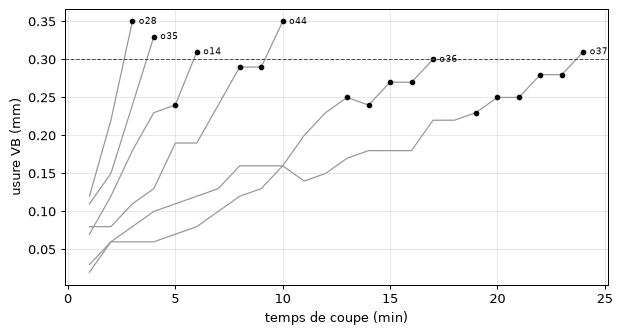

In [3]:
ordre = df.groupby("outil")["temps_coupe_min"].max().sort_values()
choix = ordre.index[np.linspace(0, len(ordre) - 1, 6).astype(int)]
fig, ax = plt.subplots(figsize=(7, 3.8))
for outil in choix:
    serie = df[df["outil"] == outil]
    ax.plot(serie["temps_coupe_min"], serie[cible], "-", color="0.6", linewidth=1)
    test = serie[est_test.loc[serie.index]]
    ax.plot(test["temps_coupe_min"], test[cible], "o", color="black", markersize=3.5)
    ax.text(serie["temps_coupe_min"].iloc[-1] + 0.3, serie[cible].iloc[-1], outil, fontsize=7, va="center")
ax.axhline(0.3, color="0.3", linestyle="--", linewidth=0.8)
ax.set_xlabel("temps de coupe (min)")
ax.set_ylabel("usure VB (mm)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Lecture du résultat : chaque courbe commence par un rodage rapide, se poursuit par une montée à peu près linéaire, puis accélère juste avant le retrait. Les plaquettes rapides s'usent en quelques minutes, les lentes en vingt. Le test, en noir, tombe à chaque fois dans la fin de vie, là où l'usure s'accélère et où la prévision est la plus délicate.

### Étape 4 : construire la pente lissée et la dernière mesure connue

Pour prévoir l'usure à `HORIZON` minutes, on n'a le droit qu'aux mesures jusqu'à `HORIZON` minutes plus tôt. On construit, pour chaque plaquette, la dernière usure connue (0 tant qu'aucune mesure n'existe : la plaquette est neuve) et la pente d'usure lissée. La pente est l'accroissement entre deux mesures ; le lissage exponentiel, `ewm` de pandas, la moyenne en donnant plus de poids aux accroissements récents, avec un coefficient `alpha` : proche de 1, il suit le dernier accroissement ; proche de 0, il moyenne sur un long passé. Ici `alpha=0.3`.

In [4]:
HORIZON = 4                                     # minutes de coupe
ALPHA = 0.3                                     # coefficient du lissage exponentiel
par_outil = df.groupby("outil")
for colonne in ["vitesse_coupe_m_min", "avance_mm_tr"]:
    df[colonne] = df[colonne].fillna(par_outil[colonne].transform("first"))
accroissement = par_outil[cible].diff().fillna(df[cible])                  # la première mesure part de 0
pente_lissee = accroissement.groupby(df["outil"]).transform(lambda s: s.ewm(alpha=ALPHA, adjust=False).mean())


def connue(serie, pas=HORIZON):
    """Valeur de la serie `pas` mesures plus tôt, la même plaquette ; 0 avant la première mesure."""
    return serie.groupby(df["outil"]).shift(pas).fillna(0.0)


X = pd.DataFrame({"usure_connue": connue(df[cible]), "pente_connue": connue(pente_lissee),
                  "temps_coupe_min": df["temps_coupe_min"], "vitesse_coupe_m_min": df["vitesse_coupe_m_min"],
                  "avance_mm_tr": df["avance_mm_tr"], "nu": (df["revetement"] == "nu").astype(int)})
y = df[cible]
X_train, X_test = X[~est_test], X[est_test]
y_train, y_test = y[~est_test], y[est_test]
print(X.head(4).round(3).to_string())

   usure_connue  pente_connue  temps_coupe_min  vitesse_coupe_m_min  avance_mm_tr  nu
0           0.0           0.0                1                171.0          0.21   0
1           0.0           0.0                2                171.0          0.21   0
2           0.0           0.0                3                171.0          0.21   0
3           0.0           0.0                4                171.0          0.21   0


### Étape 5 : construire le modèle de départ

Le modèle de départ est un lissage exponentiel : la prévision est la dernière usure connue, augmentée de la pente lissée multipliée par le nombre de minutes à prévoir. Il n'a pas de paramètre à apprendre : le seul réglage est `alpha`.

In [5]:
# Solution :
def prevoir_lissage(X_donnees, horizon=HORIZON):
    return X_donnees["usure_connue"] + horizon * X_donnees["pente_connue"]


y_pred = prevoir_lissage(X_test)
# Fin de la solution

### Étape 6 : mesurer sur la base de test

On lit l'erreur relative moyenne (MAPE) et l'erreur absolue moyenne (MAE) en mm. Deux témoins servent de comparaison : la persistance, qui répond la dernière usure connue, et la moyenne de l'apprentissage. Le tableau final décrit la prévision du modèle de départ à d'autres horizons, sans rien choisir : plus on regarde loin, plus l'erreur croît.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error as mape

score_depart = mape(y_test, y_pred)
mape_persistance = mape(y_test, X_test["usure_connue"])
mape_moyenne = mape(y_test, np.full(len(y_test), y_train.mean()))
print(f"MAPE : {score_depart:.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.4f} mm")
biais = (y_test - y_pred).mean()
print(f"écart moyen, mesure moins prévision : {biais:+.4f} mm")
print(f"MAPE de la persistance : {mape_persistance:.4f}")
print(f"MAPE de la moyenne de l'apprentissage : {mape_moyenne:.4f}")
print("MAPE selon l'horizon (minutes), lissage puis persistance :")
for h in (1, 2, 3, 4, 6):
    X_h = pd.DataFrame({"usure_connue": connue(df[cible], h), "pente_connue": connue(pente_lissee, h)})[est_test]
    print(f"  {h} : {mape(y_test, prevoir_lissage(X_h, h)):.4f}, {mape(y_test, X_h['usure_connue']):.4f}")

MAPE : 0.2035
MAE : 0.0643 mm
écart moyen, mesure moins prévision : +0.0272 mm
MAPE de la persistance : 0.4252
MAPE de la moyenne de l'apprentissage : 0.5067
MAPE selon l'horizon (minutes), lissage puis persistance :
  1 : 0.0515, 0.1219
  2 : 0.0618, 0.2185
  3 : 0.1005, 0.3178
  4 : 0.2035, 0.4252
  6 : 0.3457, 0.5700


Lecture du résultat : la MAPE du lissage est de 0,2035, soit 20,3 % d'erreur relative, pour une erreur absolue moyenne de 0,064 mm. La persistance est loin derrière (0,4252), car l'usure continue de croître pendant l'horizon. L'erreur grandit avec l'horizon : un à deux minutes sont bien prévues, six minutes beaucoup moins. En fin de vie, la pente s'accélère : en moyenne, la prévision du lissage est au-dessous de la mesure, de 0,027 mm, car il ne connaît que le passé de la plaquette.

## Pour aller plus loin : donner au modèle la durée de vie de la plaquette

Le modèle de départ de l'étape 5 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. Le fabricant des plaquettes fournit une loi de Taylor : la durée de vie T vaut 20 min à 150 m/min avec une avance de 0,2 mm/tr pour un outil nu ; elle varie comme V⁻⁴ (exposant n = 0,25) et comme f⁻⁰·⁵, et le revêtement tialn la multiplie par 1,7. Le rapport du temps de coupe à cette durée de vie, `avancement`, situe la plaquette sur sa courbe d'usure. La première cellule compare, sur une validation chronologique interne à l'apprentissage (le dernier quart de l'apprentissage de chaque plaquette), le modèle de départ et des régressions de l'accroissement d'usure. La seconde mesure le modèle retenu une seule fois sur le test. Les lectures sont imprimées par les cellules elles-mêmes.

In [7]:
# Solution :
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# durée de vie de Taylor : 20 min à 150 m/min, 0,2 mm/tr, outil nu ; V puissance -4, f puissance -0,5, revêtement x 1,7
duree_de_vie = 20 * (150 / X["vitesse_coupe_m_min"]) ** 4 * (0.2 / X["avance_mm_tr"]) ** 0.5 * np.where(X["nu"] == 1, 1.0, 1.7)
X_plus = X.assign(avancement=X["temps_coupe_min"] / duree_de_vie)
apprentissage = df[~est_test]
n_app = apprentissage.groupby("outil")["temps_coupe_min"].transform("size")
rang_app = apprentissage.groupby("outil").cumcount(ascending=False)
est_valid = rang_app < np.ceil(0.25 * n_app)
sous_train, valid = apprentissage.index[~est_valid], apprentissage.index[est_valid]
accrois = y - X["usure_connue"]                                        # ce que l'usure ajoutera pendant l'horizon
colonnes = {
    "régression sur la pente lissée et l'usure connue": ["pente_connue", "usure_connue"],
    "ajout de l'avancement de Taylor": ["pente_connue", "usure_connue", "avancement"],
    "forêt aléatoire, toutes les variables": list(X_plus.columns)}
candidats = {nom: (RandomForestRegressor(random_state=GRAINE) if "forêt" in nom else LinearRegression(), cols)
             for nom, cols in colonnes.items()}
notes_valid = {"lissage exponentiel (modèle de départ)": mape(y[valid], prevoir_lissage(X.loc[valid]))}
for nom, (estimateur, cols) in candidats.items():
    estimateur.fit(X_plus.loc[sous_train, cols], accrois[sous_train])
    prediction = X.loc[valid, "usure_connue"] + estimateur.predict(X_plus.loc[valid, cols])
    notes_valid[nom] = mape(y[valid], prediction)
for nom, note in notes_valid.items():
    print(f"{nom} : MAPE de validation {note:.4f}")
nom_retenu = min(notes_valid, key=notes_valid.get)
print("modèle retenu par la validation chronologique :", nom_retenu)
# Fin de la solution

lissage exponentiel (modèle de départ) : MAPE de validation 0.3572
régression sur la pente lissée et l'usure connue : MAPE de validation 0.2689
ajout de l'avancement de Taylor : MAPE de validation 0.0481
forêt aléatoire, toutes les variables : MAPE de validation 0.0760
modèle retenu par la validation chronologique : ajout de l'avancement de Taylor


In [8]:
# Solution :
estimateur, cols = candidats.get(nom_retenu, (None, None))
if estimateur is None:
    mape_retenu = score_depart
else:
    estimateur.fit(X_plus.loc[X_train.index, cols], accrois[X_train.index])
    mape_retenu = mape(y_test, X_test["usure_connue"] + estimateur.predict(X_plus.loc[X_test.index, cols]))
print(f"{nom_retenu}, mesuré une fois sur le test : MAPE {mape_retenu:.4f}")
print(f"écart avec le modèle de départ : {mape_retenu - score_depart:+.4f}")
# Fin de la solution

ajout de l'avancement de Taylor, mesuré une fois sur le test : MAPE 0.0498
écart avec le modèle de départ : -0.1536


## Le score de référence

Le score publié est la MAPE du modèle de départ de l'étape 5 sur la base de test : plus elle est petite, meilleur est le modèle. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [9]:
import hashlib

score = mape(y_test, prevoir_lissage(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE mape = %.4f" % score)

EMPREINTE_TEST = 111d18b6da1dd27e240915cba8d01624af7b85421328e535287f6a41baef9c45
SCORE_REFERENCE mape = 0.2035


## Synthèse

1. Une série temporelle se découpe dans l'ordre du temps : le test est le dernier quart de chaque plaquette, et l'apprentissage ne contient que des mesures antérieures. Les séries sont de longueurs très inégales, et la coupure se fait dans chacune.
2. La persistance est le point de comparaison de toute prévision : elle donne une MAPE de 0,4252 à 4 minutes. Le lissage exponentiel, qui ajoute la pente lissée, la ramène à 0,2035.
3. Plus l'horizon est lointain, plus la prévision se dégrade : le lissage seul ne connaît pas la fin de vie qui approche.
4. La loi de Taylor apporte l'information qui manque : en validation chronologique, la MAPE passe de 0,3572 pour le lissage à 0,0481 avec l'avancement, devant la forêt aléatoire (0,0760), qui doit retrouver seule la forme de la courbe.
5. Le modèle retenu par la validation chronologique est « ajout de l'avancement de Taylor » ; mesuré une seule fois sur le test, il donne une MAPE de 0,0498.